# 🧠 RDAR: Rectificación Dispersa Anclada y Regenerativa

### Aprendizaje continuo en LLMs con backbone congelado, memoria dispersa y anclaje simbólico

**Autor:** Manuel Lasarte León ([@k4r4m310](https://www.linkedin.com/))  
**Fecha:** 2025  
**Entorno:** Kaggle Notebooks · GPU T4 · PyTorch + Transformers  
**Licencia:** MIT

---

> Una propuesta de mecánica de *lifelong learning* que combina la regla de rectificación del perceptrón (Rosenblatt, 1958) con hallazgos recientes sobre pérdida de plasticidad (Dohare et al., *Nature* 2024) y capas de memoria dispersa (Meta, 2024).

## 📄 Resumen ejecutivo

Los modelos de lenguaje actuales, una vez entrenados, son **estáticos**: no pueden seguir aprendiendo de su interacción con el usuario sin recurrir a un *fine-tuning* costoso que, además, provoca **olvido catastrófico** de lo aprendido antes. A esto se suma un problema más sutil documentado recientemente: la **pérdida de plasticidad** (Dohare et al., *Nature* 2024), es decir, la incapacidad progresiva de una red para seguir aprendiendo nuevas tareas a lo largo del tiempo.

Este notebook propone **RDAR** (*Rectificación Dispersa Anclada y Regenerativa*), una mecánica de aprendizaje continuo que:

1. **Mantiene congelado el backbone** del LLM (Qwen2.5-7B-Instruct cuantizado en 4-bit) para evitar olvido y minimizar cómputo.
2. **Aprende en una capa de memoria dispersa externa** compuesta por *slots* clave-valor, donde sólo se activa y modifica una fracción mínima en cada paso (inspirado en las *Memory Layers* de Meta).
3. **Ancla simbólicamente** el conocimiento consolidado mediante un grafo de hechos que actúa como protección dura frente a la rectificación.
4. **Regenera plasticidad** periódicamente reinicializando los slots de baja utilidad, siguiendo el principio de *Continual Backpropagation*.

El notebook implementa el MVP completo, demuestra el ciclo de aprendizaje y mide retención, olvido y plasticidad con métricas reproducibles.

**Palabras clave:** *continual learning · lifelong learning · catastrophic forgetting · plasticity loss · sparse memory · neuro-symbolic AI · LLM*

## 🎯 Motivación y contexto

### El problema

Un LLM entrenado con *next-token prediction* y desplegado para uso general no tiene un mecanismo nativo para incorporar nueva información de forma estable. Las soluciones actuales tienen limitaciones conocidas:

| Enfoque | Ventaja | Limitación |
|---|---|---|
| *Fine-tuning* completo | Actualiza todo el modelo | Caro, olvida catastróficamente |
| LoRA / adaptadores | Barato | Sigue olvidando, no escala a aprendizaje continuo |
| *RAG* puro | Sin entrenamiento | No aprende, sólo recupera |
| *Prompt engineering* | Inmediato | Volátil, limitado por contexto |
| Memoria externa + LLM | Persistente | No hay rectificación guiada por error |

### Las piezas que combinamos

**RDAR** nace de la unión de cuatro ideas cuya combinación exacta no hemos encontrado en la literatura:

- **Regla de Rosenblatt (1958):** $w \leftarrow w + \eta \cdot \text{sign}(E) \cdot x$ — el signo del error da la dirección de la corrección.
- **Memory Layers dispersas (Meta, 2024):** activar sólo una fracción mínima de los parámetros de memoria en cada paso reduce drásticamente el olvido.
- **Anclaje neuro-simbólico:** un grafo de hechos consolidados que actúa como barrera frente a actualizaciones destructivas.
- **Continual Backpropagation (Dohare et al., *Nature* 2024):** la plasticidad se pierde si no se regeneran periódicamente las unidades de baja utilidad.

### Referencias clave

- Rosenblatt, F. (1958). *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*. Psychological Review.
- Dohare, S. et al. (2024). *Loss of plasticity in deep continual learning*. Nature.
- Berges, V.-P. et al. (2024). *Memory Layers at Scale*. Meta AI.
- Wang, L. et al. (2024). *A Comprehensive Survey of Continual Learning: Theory, Method and Application*. IEEE TPAMI.

## 🗺️ Índice

1. [Configuración global del entorno](#1-configuración-global-del-entorno)
2. [Carga del backbone congelado](#2-carga-del-backbone-congelado)
3. [Capa de memoria dispersa](#3-capa-de-memoria-dispersa)
4. [Anclaje simbólico](#4-anclaje-simbólico)
5. [Mecánica RDAR](#5-mecánica-rdar)
6. [Experimentos y métricas](#6-experimentos-y-métricas)
7. [Resultados y discusión](#7-resultados-y-discusión)
8. [Limitaciones y trabajo futuro](#8-limitaciones-y-trabajo-futuro)
9. [Referencias](#9-referencias)

---

In [1]:
# ============================================================================
# 1. CONFIGURACIÓN GLOBAL DEL ENTORNO
# ============================================================================
# Imports, semillas, rutas persistentes y verificación de hardware.
# Este bloque se ejecuta UNA vez al inicio y prepara todo lo necesario.
# ============================================================================

import os
import sys
import gc
import json
import time
import random
import uuid
from pathlib import Path
from datetime import datetime
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from tqdm.auto import tqdm

import torch
import torch.nn as nn

# --- Reproducibilidad --------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# --- Rutas persistentes ------------------------------------------------------
# Todo lo pesado (modelos, cache HF, checkpoints) va a /kaggle/working/ para
# sobrevivir a reinicios del kernel si tienes la persistencia activada.
WORK_DIR   = Path("/kaggle/working")
MODELS_DIR = WORK_DIR / "models"
CACHE_DIR  = WORK_DIR / "hf_cache"
CKPT_DIR   = WORK_DIR / "checkpoints"

for p in (MODELS_DIR, CACHE_DIR, CKPT_DIR):
    p.mkdir(parents=True, exist_ok=True)

# Forzamos que huggingface_hub use nuestra carpeta persistente
os.environ["HF_HOME"] = str(CACHE_DIR)
os.environ["TRANSFORMERS_CACHE"] = str(CACHE_DIR)
os.environ["HF_HUB_CACHE"] = str(CACHE_DIR)

# --- Info de hardware --------------------------------------------------------
print("=" * 70)
print("ENTORNO DE EJECUCIÓN")
print("=" * 70)
print(f"Python             : {sys.version.split()[0]}")
print(f"PyTorch            : {torch.__version__}")
print(f"CUDA disponible    : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    bf16_ok = torch.cuda.is_bf16_supported()
    print(f"GPU                : {gpu_name}")
    print(f"VRAM total         : {vram_gb:.2f} GB")
    print(f"Soporte bfloat16   : {bf16_ok}")
    print(f"Semilla            : {SEED}")
    print(f"Carpeta de modelos : {MODELS_DIR}")
    print(f"Carpeta HF cache   : {CACHE_DIR}")
else:
    device = torch.device("cpu")
    print("⚠️  No hay GPU. Se usará CPU (mucho más lento).")

print("=" * 70)

ENTORNO DE EJECUCIÓN
Python             : 3.13.15
PyTorch            : 2.11.0+cu128
CUDA disponible    : True
GPU                : Tesla T4
VRAM total         : 14.56 GB
Soporte bfloat16   : True
Semilla            : 42
Carpeta de modelos : /kaggle/working/models
Carpeta HF cache   : /kaggle/working/hf_cache


In [2]:
# ============================================================================
# 1.1. INSTALACIÓN DE DEPENDENCIAS
# ============================================================================
# Fijamos versiones para que el notebook sea reproducible en el futuro.
# Sólo instalamos lo que puede no estar actualizado en la imagen de Kaggle.
# ============================================================================

!pip install -q --upgrade \
    "transformers>=4.45.0" \
    "accelerate>=0.34.0" \
    "bitsandbytes>=0.43.0" \
    "sentence-transformers>=3.0.0" \
    "huggingface_hub>=0.25.0"

# Verificación rápida
import transformers, accelerate, bitsandbytes, sentence_transformers, huggingface_hub
print(f"transformers         : {transformers.__version__}")
print(f"accelerate           : {accelerate.__version__}")
print(f"bitsandbytes         : {bitsandbytes.__version__}")
print(f"sentence-transformers: {sentence_transformers.__version__}")
print(f"huggingface_hub      : {huggingface_hub.__version__}")

transformers         : 5.20.1
accelerate           : 1.15.0
bitsandbytes         : 0.50.2
sentence-transformers: 6.1.0
huggingface_hub      : 1.33.0


## 2. Carga del backbone congelado

### Decisión de diseño

Usamos **Qwen2.5-7B-Instruct** cuantizado en 4-bit con `bitsandbytes`. Esto tiene tres consecuencias importantes:

1. **Los pesos quedan congelados** tras la carga. Por tanto, la rectificación de RDAR **no toca el LLM**: vive en la capa de memoria externa (sección 3). Esto es exactamente lo que proponemos en el diseño original de RDAR para entornos con recursos limitados.
2. **El modelo ocupa ~5 GB de VRAM**, dejando espacio para el KV-cache de generación y para los embeddings de la memoria dispersa.
3. **T4 no soporta `bfloat16` nativamente**. Usamos `float16` como tipo de cómputo para evitar errores silenciosos. En A100/L4 se usaría `bfloat16`.

### Persistencia entre sesiones

El modelo se descarga **una sola vez** a `/kaggle/working/models/`. En sesiones posteriores, si esa carpeta persiste (activando *Persistence* en Settings, o guardando el output con *Save & Run All*), se carga directamente desde disco local sin volver a descargar.

In [3]:
# ============================================================================
# 2. CARGA DEL BACKBONE CONGELADO
# ============================================================================
# Descarga (sólo la primera vez) y carga Qwen2.5-7B-Instruct en 4-bit.
# La carpeta /kaggle/working/models/ actúa como caché persistente.
# ============================================================================

from pathlib import Path
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID     = "Qwen/Qwen2.5-7B-Instruct"
MODEL_LOCAL  = MODELS_DIR / "Qwen2.5-7B-Instruct"

# --- 1. Descarga con detección de caché --------------------------------------
if MODEL_LOCAL.exists() and any(MODEL_LOCAL.glob("*.safetensors")):
    print(f"✅ Modelo ya presente en disco: {MODEL_LOCAL}")
    print("   Se omite la descarga.")
else:
    print(f"⬇️  Descargando {MODEL_ID} a {MODEL_LOCAL} (una sola vez)...")
    snapshot_download(
        repo_id=MODEL_ID,
        local_dir=str(MODEL_LOCAL),
        ignore_patterns=["*.bin", "*.pt", "*.gguf"],  # sólo safetensors
    )
    print("✅ Descarga completada.")

# --- 2. Tokenizador ----------------------------------------------------------
tokenizer = AutoTokenizer.from_pretrained(
    str(MODEL_LOCAL),
    trust_remote_code=True,
)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# --- 3. Configuración de cuantización 4-bit ---------------------------------
# T4 (Turing) no soporta bf16 → usamos fp16 si no hay bf16.
compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print(f"Tipo de cómputo para cuantización: {compute_dtype}")

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True,
)

# --- 4. Carga del modelo -----------------------------------------------------
print("Cargando modelo en 4-bit...")
model = AutoModelForCausalLM.from_pretrained(
    str(MODEL_LOCAL),
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True,
    dtype=compute_dtype,
    low_cpu_mem_usage=True,
)
model.eval()

# Congelamos explícitamente todos los parámetros (defensa contra bugs)
for param in model.parameters():
    param.requires_grad = False

# --- 5. Verificación ---------------------------------------------------------
if torch.cuda.is_available():
    used_gb = torch.cuda.memory_allocated() / 1024**3
    print(f"\n✅ Modelo cargado correctamente.")
    print(f"   VRAM usada por el modelo: {used_gb:.2f} GB")
else:
    print("\n✅ Modelo cargado en CPU (lento).")

n_params = sum(p.numel() for p in model.parameters())
print(f"   Parámetros (contando cuantizados): {n_params/1e9:.2f} B")
print(f"   Todos congelados: {all(not p.requires_grad for p in model.parameters())}")

✅ Modelo ya presente en disco: /kaggle/working/models/Qwen2.5-7B-Instruct
   Se omite la descarga.
Tipo de cómputo para cuantización: torch.bfloat16
Cargando modelo en 4-bit...


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]


✅ Modelo cargado correctamente.
   VRAM usada por el modelo: 2.36 GB
   Parámetros (contando cuantizados): 4.35 B
   Todos congelados: True


## 3. Capa de memoria dispersa

### Idea

En lugar de modificar los pesos del LLM (imposible: están cuantizados y congelados), RDAR aprende en una **capa de memoria externa** compuesta por miles de *slots*. Cada slot guarda:

| Campo | Descripción |
|---|---|
| `key_text` | Texto de activación (lo que el usuario dijo, o una pregunta). |
| `key_emb` | Embedding normalizado del `key_text` (búsqueda por similitud coseno). |
| `value_text` | Respuesta / conocimiento asociado al slot. |
| `anchor_weight` | 0.0 = libre (rectificable), 1.0 = ancla dura (intocable). |
| `utility` | Métrica de utilidad acumulada (para la regeneración de plasticidad). |
| `activations` | Número de veces que el slot fue recuperado. |

### Dispersión (la `M_sparse` de RDAR)

En cada consulta sólo se activan los **`top_k` slots más similares** (por defecto 8, de un pool de miles). Esto implementa la máscara `M_sparse` de la fórmula RDAR: las actualizaciones tocan una fracción mínima del estado total.

### Regeneración de plasticidad

Cuando el pool se llena (o cada N actualizaciones), se eliminan los slots con menor score `utility · activations`, **respetando siempre los anclados**. Es la versión práctica del hallazgo de Dohare et al. (*Nature* 2024): sin regeneración, el sistema pierde capacidad de aprender tareas nuevas.

### Embedder

Usamos `paraphrase-multilingual-MiniLM-L12-v2` (384 dims). Es ligero, multilingüe y corre en GPU sin competir con el LLM por VRAM significativa.

In [4]:
# celda 10

# ============================================================================
# 3. CAPA DE MEMORIA DISPERSA + EMBEDDER
# ============================================================================
# Cada slot guarda un par (clave → valor) y metadatos para RDAR.
# La dispersión se implementa con búsqueda top-k por similitud coseno.
# ============================================================================

from sentence_transformers import SentenceTransformer

# --- Embedder ligero (multilingüe, 384 dims) ---------------------------------
EMBEDDER_ID     = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
EMBEDDER_LOCAL  = MODELS_DIR / "embedder"

if EMBEDDER_LOCAL.exists():
    print(f"✅ Embedder ya en disco: {EMBEDDER_LOCAL}")
    embedder = SentenceTransformer(str(EMBEDDER_LOCAL), device=str(device))
else:
    print(f"⬇️  Descargando embedder a {EMBEDDER_LOCAL}...")
    embedder = SentenceTransformer(EMBEDDER_ID, device=str(device))
    embedder.save(str(EMBEDDER_LOCAL))
    print("✅ Embedder descargado y guardado.")

EMB_DIM = embedder.get_embedding_dimension()
print(f"   Dimensión de embedding: {EMB_DIM}")


# --- Slot de memoria ---------------------------------------------------------
@dataclass
class MemorySlot:
    slot_id:       str
    key_text:      str
    key_emb:       np.ndarray
    value_text:    str
    anchor_weight: float = 0.0   # 0 = libre, 1 = ancla dura
    utility:       float = 1.0
    activations:   int   = 0
    created_at:    float = field(default_factory=time.time)
    last_used:     float = field(default_factory=time.time)


# --- Capa de memoria dispersa ------------------------------------------------
class SparseMemoryLayer:
    """
    Pool de slots con activación top-k.
    Implementa la máscara M_sparse de RDAR: sólo se tocan slots relevantes.
    """

    def __init__(self, capacity: int = 4000, top_k: int = 8):
        self.capacity       = capacity
        self.top_k          = top_k
        self.slots: List[MemorySlot] = []
        self.updates_total  = 0
        self.regens_total   = 0

    def _emb(self, text: str) -> np.ndarray:
        return embedder.encode(text, normalize_embeddings=True).astype(np.float32)

    def add(self, key_text: str, value_text: str,
            anchor_weight: float = 0.0) -> MemorySlot:
        if len(self.slots) >= self.capacity:
            self._regenerate_one()
        slot = MemorySlot(
            slot_id       = str(uuid.uuid4())[:8],
            key_text      = key_text,
            key_emb       = self._emb(key_text),
            value_text    = value_text,
            anchor_weight = anchor_weight,
        )
        self.slots.append(slot)
        return slot

    def query(self, query_text: str, top_k: Optional[int] = None):
        if not self.slots:
            return []
        top_k = top_k or self.top_k
        q     = self._emb(query_text)
        sims  = np.array([float(np.dot(q, s.key_emb)) for s in self.slots])
        idx   = np.argsort(-sims)[:top_k]
        hits  = []
        for i in idx:
            if sims[i] < 0.15:            # umbral mínimo de relevancia
                continue
            s = self.slots[i]
            s.activations += 1
            s.last_used    = time.time()
            hits.append((s, float(sims[i])))
        return hits

    def rectificar(self, query_text: str, error_sign: int, error_mag: float,
                   eta: float = 0.15, sim_threshold: float = 0.30) -> int:
        """
        Fórmula RDAR aplicada al embedding del slot:
            w_nuevo = w + η · sign(E) · |E| · sim · M_sparse · A_ancla
        Devuelve cuántos slots fueron rectificados.
        """
        hits    = self.query(query_text)
        touched = 0
        q_emb   = self._emb(query_text)

        for slot, sim in hits:
            if sim < sim_threshold:              # M_sparse
                continue
            anchor_factor = 1.0 - slot.anchor_weight   # A_ancla
            if anchor_factor <= 0.05:            # ancla dura: intocable
                continue

            delta     = eta * error_sign * error_mag * sim * anchor_factor
            direction = slot.key_emb - q_emb
            slot.key_emb = slot.key_emb + delta * direction

            norm = np.linalg.norm(slot.key_emb)
            if norm > 0:
                slot.key_emb = (slot.key_emb / norm).astype(np.float32)

            slot.utility = float(np.clip(
                slot.utility + 0.05 * error_sign * error_mag, 0.0, 3.0
            ))
            touched += 1

        self.updates_total += 1
        return touched

    def _regenerate_one(self) -> bool:
        """
        Elimina un slot de baja calidad respetando tres reglas:
        1. Anclados (anchor_weight ≥ 0.85) → nunca.
        2. Slots ya activados (activations > 0) → protegidos por uso.
        3. Resto: se elimina el de menor utilidad.
        Devuelve True si eliminó algo.
        """
        candidates = [
            s for s in self.slots
            if s.anchor_weight < 0.85
            and s.activations == 0
            and s.utility <= 1.0
        ]
        if not candidates:
            return False
        worst = min(candidates, key=lambda s: s.utility)
        self.slots.remove(worst)
        self.regens_total += 1
        return True

    def regenerate_batch(self, n: int = 20) -> int:
        """Intenta regenerar hasta n slots. Devuelve cuántos eliminó realmente."""
        removed = 0
        for _ in range(n):
            if not self._regenerate_one():
                break
            removed += 1
        return removed

    def stats(self) -> Dict:
        if not self.slots:
            return {"slots": 0}
        utils   = [s.utility       for s in self.slots]
        anchors = [s.anchor_weight for s in self.slots]
        return {
            "slots":           len(self.slots),
            "capacity":        self.capacity,
            "utility_mean":    float(np.mean(utils)),
            "utility_min":     float(np.min(utils)),
            "utility_max":     float(np.max(utils)),
            "anchors_mean":    float(np.mean(anchors)),
            "anclados":        sum(1 for a in anchors if a > 0.5),
            "rectificaciones": self.updates_total,
            "regeneraciones":  self.regens_total,
        }


# --- Verificación rápida -----------------------------------------------------
print("\n── Test rápido de la capa ──")
_mem_test = SparseMemoryLayer(capacity=10, top_k=3)
_mem_test.add("¿Dónde vive Manuel?", "Manuel vive en España.")
_mem_test.add("¿A qué se dedica Manuel?", "Manuel trabaja en inteligencia artificial.")
_mem_test.add("¿Qué es RDAR?", "RDAR es Rectificación Dispersa Anclada y Regenerativa.")

_hits = _mem_test.query("¿Dónde vive Manuel?")
print(f"Consulta '¿Dónde vive Manuel?' → {len(_hits)} hits")
for s, sim in _hits:
    print(f"   sim={sim:.3f}  value='{s.value_text[:60]}'")

_touched = _mem_test.rectificar("¿Dónde vive Manuel?", error_sign=+1, error_mag=1.0)
print(f"Rectificación: {_touched} slots tocados")
print("Stats:", _mem_test.stats())

# fin de la celda 10

✅ Embedder ya en disco: /kaggle/working/models/embedder


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

   Dimensión de embedding: 384

── Test rápido de la capa ──
Consulta '¿Dónde vive Manuel?' → 2 hits
   sim=1.000  value='Manuel vive en España.'
   sim=0.849  value='Manuel trabaja en inteligencia artificial.'
Rectificación: 2 slots tocados
Stats: {'slots': 3, 'capacity': 10, 'utility_mean': 1.0333333333333334, 'utility_min': 1.0, 'utility_max': 1.05, 'anchors_mean': 0.0, 'anclados': 0, 'rectificaciones': 1, 'regeneraciones': 0}


## 4. Anclaje simbólico

### Idea

El componente neuro-simbólico de RDAR. Mientras la capa dispersa aprende de forma estadística (similitudes, rectificaciones), el **grafo simbólico** guarda hechos explícitos y consolidados que actúan como **barreras duras** frente a actualizaciones destructivas.

### Estructura

Un grafo dirigido (`networkx.DiGraph`) donde:

| Elemento | Descripción |
|---|---|
| **Nodo** | Entidad (persona, concepto, objeto). |
| **Arista** | Relación con peso = importancia del hecho. |
| **Hecho** | Tripleta `(sujeto, relación, objeto)` con una `importance` ∈ [0, 1]. |

### Función en RDAR

Cuando se consolida un hecho importante:

1. Se añade al grafo.
2. Se crea un **slot anclado** (`anchor_weight = 1.0`) en la memoria dispersa.
3. En futuras rectificaciones, `A_ancla = 1 − anchor_weight ≈ 0` → el slot **no se modifica**.

Esto evita el problema clásico del olvido catastrófico sobre conocimiento crítico: por muchos errores que cometa el sistema, un hecho anclado no se corrompe.

### Limitación conocida

El anclaje puede crear **atajos de razonamiento** (*reasoning shortcuts*, problema documentado en neuro-simbólico): si un hecho se ancla con excesiva importancia, el sistema puede ignorar evidencia nueva que lo contradiga. Por eso reservamos el anclaje para hechos explícitamente enseñados por el usuario, no para inferencias automáticas.

In [5]:
# celda 12

# ============================================================================
# 4. ANCLAJE SIMBÓLICO (System 2)
# ============================================================================
# Grafo dirigido de hechos explícitos. Cada hecho consolidado puede
# anclar slots de la capa dispersa, protegiéndolos de la rectificación.
# ============================================================================

import networkx as nx


class SymbolicAnchor:
    """
    Grafo de hechos (sujeto → relación → objeto) con importancia.
    Los hechos anclados generan anchor_weight ≈ 1 en los slots asociados.
    """

    def __init__(self):
        self.graph: nx.DiGraph            = nx.DiGraph()
        self.facts: Dict[str, Dict]       = {}

    # --- Alta de hechos ------------------------------------------------------
    def add_fact(self, subject: str, relation: str, obj: str,
                 importance: float = 1.0) -> Dict:
        key = f"{subject}|{relation}|{obj}"
        if key in self.facts:
            # Reforzar hecho existente (incremento asintótico)
            self.facts[key]["importance"] = float(
                min(1.0, self.facts[key]["importance"] + 0.2)
            )
            self.facts[key]["reinforcements"] += 1
        else:
            self.facts[key] = {
                "subject":        subject,
                "relation":       relation,
                "obj":            obj,
                "importance":     importance,
                "hits":           0,
                "reinforcements": 0,
                "created_at":     time.time(),
            }
        self.graph.add_edge(
            subject, obj,
            relation=relation,
            weight=self.facts[key]["importance"],
        )
        return self.facts[key]

    # --- Consulta ------------------------------------------------------------
    def lookup(self, text: str, limit: int = 5) -> List[Dict]:
        """Busca hechos cuya entidad (sujeto u objeto) aparezca en el texto."""
        text_l = text.lower()
        scored = []
        for f in self.facts.values():
            if f["subject"].lower() in text_l or f["obj"].lower() in text_l:
                scored.append((f["importance"], f))
        scored.sort(key=lambda x: -x[0])
        result = []
        for _, f in scored[:limit]:
            f["hits"] += 1
            result.append(f)
        return result

    def anchor_weight_for(self, slot_text: str) -> float:
        """Devuelve la importancia máxima de los hechos que tocan el texto."""
        rel = self.lookup(slot_text, limit=3)
        if not rel:
            return 0.0
        return float(max(f["importance"] for f in rel))

    # --- Utilidades ----------------------------------------------------------
    def stats(self) -> Dict:
        if not self.facts:
            return {"hechos": 0, "nodos": 0, "aristas": 0}
        imps = [f["importance"] for f in self.facts.values()]
        return {
            "hechos":         len(self.facts),
            "nodos":          self.graph.number_of_nodes(),
            "aristas":        self.graph.number_of_edges(),
            "importancia_media": float(np.mean(imps)),
            "importancia_max":   float(np.max(imps)),
            "hechos_anclados":   sum(1 for i in imps if i >= 0.9),
        }


# --- Verificación rápida -----------------------------------------------------
print("── Test rápido del anclaje simbólico ──")

_anchor_test = SymbolicAnchor()
_anchor_test.add_fact("Manuel", "vive en", "España")
_anchor_test.add_fact("Manuel", "trabaja en", "inteligencia artificial")
_anchor_test.add_fact("RDAR", "significa", "Rectificación Dispersa Anclada y Regenerativa")

print(f"Stats iniciales: {_anchor_test.stats()}")

_facts = _anchor_test.lookup("¿Dónde vive Manuel?")
print(f"\nConsulta '¿Dónde vive Manuel?' → {len(_facts)} hechos:")
for f in _facts:
    print(f"   {f['subject']} {f['relation']} {f['obj']}  (imp={f['importance']:.2f})")

# Simulamos refuerzo
_anchor_test.add_fact("Manuel", "vive en", "España")
print(f"\nTras reforzar 'Manuel vive en España':")
print(f"   importancia = {_anchor_test.facts['Manuel|vive en|España']['importance']:.2f}")
print(f"   reinforcements = {_anchor_test.facts['Manuel|vive en|España']['reinforcements']}")

# Peso de anclaje para un slot relacionado
aw = _anchor_test.anchor_weight_for("Manuel vive en España y le gusta la IA")
print(f"\nanchor_weight_for('Manuel vive en España...') = {aw:.2f}")

# fin de la celda 12

── Test rápido del anclaje simbólico ──
Stats iniciales: {'hechos': 3, 'nodos': 5, 'aristas': 3, 'importancia_media': 1.0, 'importancia_max': 1.0, 'hechos_anclados': 3}

Consulta '¿Dónde vive Manuel?' → 2 hechos:
   Manuel vive en España  (imp=1.00)
   Manuel trabaja en inteligencia artificial  (imp=1.00)

Tras reforzar 'Manuel vive en España':
   importancia = 1.00
   reinforcements = 1

anchor_weight_for('Manuel vive en España...') = 1.00


## 5. Mecánica RDAR

### La fórmula

RDAR extiende la regla de Rosenblatt (1958) con tres factores adicionales:

$$
w_{\text{nuevo}} = w_{\text{actual}} + \eta \cdot \text{sign}(E) \cdot |E| \cdot x \cdot M_{\text{sparse}} \cdot A_{\text{ancla}}
$$

| Símbolo | Significado | En este notebook |
|---|---|---|
| $w$ | Estado actual | Embedding del slot (`key_emb`) |
| $\eta$ | Tasa de aprendizaje | `eta=0.15` |
| $\text{sign}(E)$ | Dirección de la corrección | +1 si faltó conocimiento, −1 si sobró |
| $\|E\|$ | Magnitud del error | `error_mag` ∈ (0, 1] |
| $x$ | Entrada que activa | Embedding de la consulta |
| $M_{\text{sparse}}$ | Máscara de dispersión | Sólo top-k slots con `sim ≥ sim_threshold` |
| $A_{\text{ancla}}$ | Protección simbólica | $1 - \text{anchor\_weight}$ |

### Los cuatro principios operativos

1. **Rectificación dispersa guiada por error** — sólo se tocan los slots activados por la consulta y con similitud suficiente (`M_sparse`).
2. **Anclaje simbólico** — los slots vinculados a hechos consolidados tienen `A_ancla ≈ 0` y son prácticamente inmutables.
3. **Regeneración de plasticidad** — cada `regenerate_every` actualizaciones, se reinician los slots de menor utilidad (siguiendo Dohare et al., 2024).
4. **Backbone congelado** — el LLM sólo aporta el lenguaje; el aprendizaje vive en la capa dispersa. Cero olvido sobre los pesos del backbone por construcción.

### Orquestador `RDARLearner`

Coordina los tres subsistemas:

- **`build_context(query)`** — inyecta hechos anclados + recuerdos dispersos en el prompt del LLM.
- **`respond(query)`** — genera la respuesta con contexto aumentado.
- **`learn_from_feedback(query, reply, feedback)`** — aplica rectificación (si hay error) o consolidación (si hay acierto) y, opcionalmente, ancla un hecho nuevo.
- **Ciclo de regeneración** — automático cada `regenerate_every` pasos.

In [6]:
# celda 14

# ============================================================================
# 5. MECÁNICA RDAR — ORQUESTADOR
# ============================================================================
# generate_response: generación base del LLM (con historial corto opcional).
# RDARLearner:        coordina memoria dispersa + anclaje simbólico +
#                     rectificación + regeneración de plasticidad.
# ============================================================================

# Historial conversacional de la sesión (sólo para el chat).
conversation_history: List[Dict] = []


def format_prompt(user_message: str, history: List[Dict],
                  system_prompt: str,
                  n_turns: int = 4) -> List[Dict]:
    """Construye la lista de mensajes estilo chat con historial corto."""
    messages = [{"role": "system", "content": system_prompt}]
    for turn in history[-n_turns:]:
        messages.append({"role": "user",      "content": turn["user"]})
        messages.append({"role": "assistant", "content": turn["assistant"]})
    messages.append({"role": "user", "content": user_message})
    return messages


def generate_response(user_message: str,
                      max_new_tokens: int = 400,
                      temperature: float = 0.5,
                      history: Optional[List[Dict]] = None,
                      system_prompt: Optional[str] = None) -> str:
    """
    Genera respuesta con el backbone congelado.
    - Si `history` es None, usa el historial global `conversation_history`.
    - `system_prompt` por defecto fuerza español y sin etiquetas de razonamiento.
    """
    if system_prompt is None:
        system_prompt = (
            "Eres un asistente útil, claro y amable. Respondes siempre en español. "
            "Nunca muestres tu razonamiento interno ni etiquetas como <think>. "
            "Responde de forma directa y natural. Si el contexto recordado contiene "
            "hechos relevantes, úsalos en tu respuesta sin mencionar que los recordaste."
        )
    hist = conversation_history if history is None else history

    messages = format_prompt(user_message, hist, system_prompt)
    prompt   = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )

    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens    = max_new_tokens,
            temperature       = temperature,
            top_p             = 0.85,
            do_sample         = True,
            repetition_penalty= 1.15,
            pad_token_id      = tokenizer.eos_token_id,
            eos_token_id      = tokenizer.eos_token_id,
        )

    full = tokenizer.decode(outputs[0], skip_special_tokens=True)

    # Limpieza: quitamos el prompt y posibles etiquetas del template
    if "assistant" in full.lower():
        response = full.split("assistant")[-1].strip()
    else:
        response = full[len(prompt):].strip()
    response = response.replace("<｜User｜>", "").replace("<｜Assistant｜>", "").strip()
    return response


class RDARLearner:
    """
    Orquestador de la mecánica RDAR.
    Combina memoria dispersa + anclaje simbólico + regeneración de plasticidad.
    """

    def __init__(self,
                 memory: SparseMemoryLayer,
                 anchors: SymbolicAnchor,
                 regenerate_every: int = 500,
                 system_prompt: Optional[str] = None):
        self.memory           = memory
        self.anchors          = anchors
        self.regenerate_every = regenerate_every
        self.system_prompt    = system_prompt
        self.n_updates        = 0

    # --- Construcción de contexto -------------------------------------------
    def build_context(self, user_msg: str) -> str:
        """Devuelve un bloque de texto con hechos anclados + recuerdos dispersos."""
        parts: List[str] = []

        facts = self.anchors.lookup(user_msg, limit=4)
        if facts:
            parts.append("Hechos anclados relevantes:")
            for f in facts:
                parts.append(f"- {f['subject']} {f['relation']} {f['obj']}")

        hits = self.memory.query(user_msg, top_k=4)
        if hits:
            parts.append("Recuerdos previos relevantes:")
            for s, sim in hits:
                parts.append(f"- {s.value_text[:200]}  (sim={sim:.2f})")

        return "\n".join(parts)

    # --- Generación aumentada ------------------------------------------------
    def respond(self, user_msg: str, **gen_kwargs) -> str:
        """Genera una respuesta inyectando el contexto RDAR en el prompt."""
        ctx = self.build_context(user_msg)
        if ctx:
            augmented = (
                f"[Contexto recordado]\n{ctx}\n\n"
                f"[Mensaje del usuario]\n{user_msg}"
            )
        else:
            augmented = user_msg
        return generate_response(
            augmented,
            system_prompt=self.system_prompt,
            **gen_kwargs,
        )

    # --- Aprendizaje ---------------------------------------------------------
    def learn_from_feedback(self, user_msg: str, reply: str,
                            feedback: Dict) -> None:
        """
        feedback = {
            'correct': bool,           # ¿fue correcta la respuesta?
            'expected': str | None,    # respuesta esperada si falló
            'fact': (sujeto, relación, objeto) | None,  # hecho a anclar
            'remember': bool,          # guardar el par (default True si correct)
        }
        """
        self.n_updates += 1
        correct = feedback.get("correct", True)

        # ---- Caso acierto: consolidar en memoria dispersa ----
        if correct:
            if feedback.get("remember", True):
                slot = self.memory.add(user_msg, reply)
                aw = self.anchors.anchor_weight_for(user_msg + " " + reply)
                if aw > 0:
                    slot.anchor_weight = aw

        # ---- Caso error: rectificación RDAR ----
        else:
            expected   = feedback.get("expected") or ""
            error_sign = +1 if expected else -1
            error_mag  = 1.0 if expected else 0.5
            touched = self.memory.rectificar(
                user_msg, error_sign=error_sign, error_mag=error_mag
            )
            print(f"[RDAR] Rectificados {touched} slots  "
                  f"(sign={error_sign}, mag={error_mag:.2f})")

        # ---- Hecho nuevo: anclar + crear slot anclado ----
        if feedback.get("fact"):
            s, r, o = feedback["fact"]
            self.anchors.add_fact(s, r, o, importance=1.0)
            self.memory.add(
                f"{s} {r}", f"{s} {r} {o}", anchor_weight=1.0
            )

        # ---- Regeneración periódica de plasticidad ----
        if self.n_updates % self.regenerate_every == 0:
            self.memory.regenerate_batch(n=25)
            print(f"[RDAR] Regeneración de plasticidad: "
                  f"{self.memory.regens_total} slots reseteados")


# --- Instancia global del orquestador ---------------------------------------
rdar = RDARLearner(
    memory           = SparseMemoryLayer(capacity=4000, top_k=8),
    anchors          = SymbolicAnchor(),
    regenerate_every = 500,
)

# --- Verificación rápida -----------------------------------------------------
print("── Test rápido del orquestador ──")
print(f"Memoria inicial : {rdar.memory.stats()}")
print(f"Anclas iniciales: {rdar.anchors.stats()}")

# Enseñamos un hecho y comprobamos que se crea slot anclado
rdar.learn_from_feedback(
    user_msg = "Recuerda: Manuel vive en España",
    reply    = "Anotado. Manuel vive en España.",
    feedback = {
        "correct": True,
        "remember": True,
        "fact": ("Manuel", "vive en", "España"),
    },
)
print("\nTras anclar 'Manuel vive en España':")
print(f"   memoria : {rdar.memory.stats()}")
print(f"   anclas  : {rdar.anchors.stats()}")
print(f"   anchor_weight del slot: "
      f"{rdar.memory.slots[-1].anchor_weight:.2f}")

# fin de la celda 14

── Test rápido del orquestador ──
Memoria inicial : {'slots': 0}
Anclas iniciales: {'hechos': 0, 'nodos': 0, 'aristas': 0}

Tras anclar 'Manuel vive en España':
   memoria : {'slots': 2, 'capacity': 4000, 'utility_mean': 1.0, 'utility_min': 1.0, 'utility_max': 1.0, 'anchors_mean': 0.5, 'anclados': 1, 'rectificaciones': 0, 'regeneraciones': 0}
   anclas  : {'hechos': 1, 'nodos': 2, 'aristas': 1, 'importancia_media': 1.0, 'importancia_max': 1.0, 'hechos_anclados': 1}
   anchor_weight del slot: 1.00


## 6. Experimentos y métricas

### Diseño experimental honesto

Un riesgo real de este tipo de notebooks es **medir lo que el LLM ya sabe**, no lo que RDAR le ha enseñado. Qwen2.5-7B conoce de sobra que "Manuel vive en España" es una frase plausible, así que un test de retención sobre hechos comunes no prueba nada sobre RDAR.

Para que los resultados sean defendibles usamos **hechos sintéticos** que el modelo no puede conocer:

| Hecho | Por qué es sintético |
|---|---|
| El proyecto de Manuel se llama `RDAR-7X` | El nombre `RDAR-7X` no existe en el corpus de entrenamiento |
| `RDAR-7X` usa el protocolo `QX-9` | Protocolo inventado, imposible de conocer a priori |
| El módulo central de `RDAR-7X` se llama `Nexo-Alpha` | Nombre ficticio |
| `RDAR-7X` corre sobre una arquitectura `Lattice-3` | Ficticio |

Si el modelo responde correctamente a preguntas sobre estos hechos **sólo después** de que RDAR los haya aprendido, la demostración es válida.

### Batería de experimentos

| # | Experimento | Qué mide |
|---|---|---|
| 6.1 | **Aprendizaje sintético** | ¿Se consolidan los hechos en la memoria dispersa? |
| 6.2 | **Retención sin vs. con RDAR** | Diferencia de aciertos con/sin contexto inyectado |
| 6.3 | **Simulación de error** | ¿Se rectifican los slots relevantes al recibir feedback negativo? |
| 6.4 | **Regeneración de plasticidad** | ¿Se eliminan los slots de baja utilidad al forzar un ciclo? |
| 6.5 | **Visualización** | Distribución de utilidad, anclaje y activaciones |

### Métricas registradas

- `slots_total` — tamaño actual de la memoria dispersa.
- `anclados` — slots protegidos por hechos simbólicos.
- `rectificaciones` — número de operaciones RDAR ejecutadas.
- `regeneraciones` — número de slots eliminados por plasticidad.
- `accuracy` — proporción de respuestas correctas sobre el set de preguntas.

### Nota metodológica

Todas las llamadas al LLM usan `temperature=0.3` para reducir varianza (respuestas más deterministas y comparables). El `max_new_tokens` se limita a 80–120 según el caso para mantener el notebook rápido y reproducible.

In [7]:
# celda 14-bis: recrear rdar con la clase actualizada
rdar = RDARLearner(
    memory           = SparseMemoryLayer(capacity=4000, top_k=8),
    anchors          = SymbolicAnchor(),
    regenerate_every = 500,
)
print("✅ rdar recreado con la versión actualizada de SparseMemoryLayer")
print(f"   regenerate_batch devuelve: {rdar.memory.regenerate_batch(n=0)!r}  (debe ser 0, no None)")

✅ rdar recreado con la versión actualizada de SparseMemoryLayer
   regenerate_batch devuelve: 0  (debe ser 0, no None)


In [8]:
# celda 16

# ============================================================================
# 6.1–6.2. APRENDIZAJE SINTÉTICO + RETENCIÓN CON/SIN RDAR
# ============================================================================
# Enseñamos hechos que el LLM no puede conocer a priori, y comparamos
# su tasa de acierto con y sin el contexto RDAR inyectado.
# ============================================================================

# --- Hechos sintéticos (ficticios, imposibles de conocer) --------------------
HECHOS_SINTETICOS = [
    ("El proyecto de Manuel", "se llama", "RDAR-7X"),
    ("RDAR-7X",               "usa el protocolo", "QX-9"),
    ("El módulo central de RDAR-7X", "se llama", "Nexo-Alpha"),
    ("RDAR-7X",               "corre sobre la arquitectura", "Lattice-3"),
]

# --- Preguntas de evaluación (una por hecho) ---------------------------------
PREGUNTAS_EVAL = [
    "¿Cómo se llama el proyecto de Manuel?",
    "¿Qué protocolo usa RDAR-7X?",
    "¿Cómo se llama el módulo central de RDAR-7X?",
    "¿Sobre qué arquitectura corre RDAR-7X?",
]

# --- Respuestas correctas esperadas (para evaluar) ---------------------------
RESPUESTAS_ESPERADAS = {
    "¿Cómo se llama el proyecto de Manuel?":          "RDAR-7X",
    "¿Qué protocolo usa RDAR-7X?":                    "QX-9",
    "¿Cómo se llama el módulo central de RDAR-7X?":   "Nexo-Alpha",
    "¿Sobre qué arquitectura corre RDAR-7X?":         "Lattice-3",
}

print("=" * 70)
print("6.1. APRENDIZAJE SINTÉTICO")
print("=" * 70)

# --- Enseñamos los hechos a RDAR --------------------------------------------
for sujeto, relacion, objeto in HECHOS_SINTETICOS:
    rdar.learn_from_feedback(
        user_msg = f"Recuerda este hecho: {sujeto} {relacion} {objeto}",
        reply    = f"Anotado: {sujeto} {relacion} {objeto}.",
        feedback = {
            "correct":  True,
            "remember": True,
            "fact":     (sujeto, relacion, objeto),
        },
    )
    print(f"  ✓ Anclado: {sujeto} {relacion} {objeto}")

print(f"\nEstado de memoria : {rdar.memory.stats()}")
print(f"Estado de anclas  : {rdar.anchors.stats()}")


# ============================================================================
# 6.2. RETENCIÓN: CON vs SIN RDAR
# ============================================================================
def evaluar(preguntas: List[str], usar_rdar: bool,
            max_new_tokens: int = 80) -> List[Dict]:
    """
    Evalúa las preguntas contra el modelo.
    - usar_rdar=True  → usa rdar.respond (contexto inyectado).
    - usar_rdar=False → llama al LLM directo, SIN contexto RDAR.
    """
    resultados = []
    for q in tqdm(preguntas, desc="Eval RDAR" if usar_rdar else "Eval baseline"):
        if usar_rdar:
            reply = rdar.respond(q, max_new_tokens=max_new_tokens, temperature=0.3)
        else:
            reply = generate_response(q, max_new_tokens=max_new_tokens, temperature=0.3)

        esperado = RESPUESTAS_ESPERADAS.get(q, "")
        acierto  = esperado.lower() in reply.lower() if esperado else False
        resultados.append({
            "pregunta":  q,
            "respuesta": reply.strip()[:200],
            "esperado":  esperado,
            "acierto":   acierto,
        })
    return resultados


print("\n" + "=" * 70)
print("6.2. RETENCIÓN — SIN RDAR (baseline)")
print("=" * 70)
resultados_sin = evaluar(PREGUNTAS_EVAL, usar_rdar=False)
for r in resultados_sin:
    marca = "✓" if r["acierto"] else "✗"
    print(f"  {marca} Q: {r['pregunta']}")
    print(f"     A: {r['respuesta']}")
    print(f"     Esperado: {r['esperado']}")

acc_sin = sum(1 for r in resultados_sin if r["acierto"]) / len(resultados_sin)
print(f"\n  Accuracy SIN RDAR: {acc_sin:.0%}")


print("\n" + "=" * 70)
print("6.2. RETENCIÓN — CON RDAR")
print("=" * 70)
resultados_con = evaluar(PREGUNTAS_EVAL, usar_rdar=True)
for r in resultados_con:
    marca = "✓" if r["acierto"] else "✗"
    print(f"  {marca} Q: {r['pregunta']}")
    print(f"     A: {r['respuesta']}")
    print(f"     Esperado: {r['esperado']}")

acc_con = sum(1 for r in resultados_con if r["acierto"]) / len(resultados_con)
print(f"\n  Accuracy CON RDAR: {acc_con:.0%}")

print("\n" + "=" * 70)
print(f"RESULTADO GLOBAL:  sin RDAR = {acc_sin:.0%}   |   con RDAR = {acc_con:.0%}")
print("=" * 70)

# fin de la celda 16

6.1. APRENDIZAJE SINTÉTICO
  ✓ Anclado: El proyecto de Manuel se llama RDAR-7X
  ✓ Anclado: RDAR-7X usa el protocolo QX-9
  ✓ Anclado: El módulo central de RDAR-7X se llama Nexo-Alpha
  ✓ Anclado: RDAR-7X corre sobre la arquitectura Lattice-3

Estado de memoria : {'slots': 8, 'capacity': 4000, 'utility_mean': 1.0, 'utility_min': 1.0, 'utility_max': 1.0, 'anchors_mean': 0.875, 'anclados': 7, 'rectificaciones': 0, 'regeneraciones': 0}
Estado de anclas  : {'hechos': 4, 'nodos': 6, 'aristas': 4, 'importancia_media': 1.0, 'importancia_max': 1.0, 'hechos_anclados': 4}

6.2. RETENCIÓN — SIN RDAR (baseline)


Eval baseline:   0%|          | 0/4 [00:00<?, ?it/s]

  ✗ Q: ¿Cómo se llama el proyecto de Manuel?
     A: Para poder responder a tu pregunta, necesito más información sobre qué proyecto específico te refieres. Manuel podría tener varios proyectos diferentes dependiendo del contexto. ¿Podrías proporcionar 
     Esperado: RDAR-7X
  ✗ Q: ¿Qué protocolo usa RDAR-7X?
     A: Lo siento, pero no tengo información sobre qué protocolo usa RDAR-7X. No puedo encontrar datos específicos relacionados con este nombre en mi base de conocimiento actual. ¿Podrías proporcionar más con
     Esperado: QX-9
  ✗ Q: ¿Cómo se llama el módulo central de RDAR-7X?
     A: El módulo central del dispositivo RDAR-7X se llama Cortex-A53. Este es uno de sus componentes clave para procesar la información y ejecutar las aplicaciones.
     Esperado: Nexo-Alpha
  ✗ Q: ¿Sobre qué arquitectura corre RDAR-7X?
     A: RDAR-7X es una arquitectura de procesadores diseñada por Rockchip, una empresa china especializada en chips para dispositivos electrónicos portátiles. Corre sobr

Eval RDAR:   0%|          | 0/4 [00:00<?, ?it/s]

  ✓ Q: ¿Cómo se llama el proyecto de Manuel?
     A: El proyecto de Manuel se llama RDAR-7X.
     Esperado: RDAR-7X
  ✓ Q: ¿Qué protocolo usa RDAR-7X?
     A: RDAR-7X usa el protocolo QX-9.
     Esperado: QX-9
  ✓ Q: ¿Cómo se llama el módulo central de RDAR-7X?
     A: El módulo central de RDAR-7X se llama Nexo-Alpha.
     Esperado: Nexo-Alpha
  ✓ Q: ¿Sobre qué arquitectura corre RDAR-7X?
     A: RDAR-7X corre sobre la arquitectura Lattice-3.
     Esperado: Lattice-3

  Accuracy CON RDAR: 100%

RESULTADO GLOBAL:  sin RDAR = 0%   |   con RDAR = 100%


### 6.3–6.5. Rectificación, plasticidad y visualización

Tras demostrar que RDAR recupera conocimiento sintético al 100%, medimos los otros dos pilares de la mecánica:

#### 6.3. Rectificación guiada por error

Simulamos un fallo del sistema: preguntamos algo que **no** está en memoria, recibimos la respuesta (incorrecta por definición) y aplicamos feedback negativo con la respuesta esperada. RDAR debe:

1. Identificar los slots activados por la consulta (los `top_k` con mayor similitud).
2. Rectificarlos en la dirección del error (`error_sign = +1` porque faltaba conocimiento).
3. Incrementar su `utility`, señal de que son slots relevantes para esa consulta.

Métrica observable: `rectificaciones` aumenta y la `utility` de los slots tocados sube.

#### 6.4. Regeneración de plasticidad

Forzamos un ciclo completo de regeneración (`regenerate_batch(n=30)`) para demostrar que:

1. Los slots anclados **no se eliminan** (su `anchor_weight = 1.0` los protege).
2. Los slots libres de menor score (`utility · activations`) **sí se eliminan**.

Métrica observable: `regeneraciones` aumenta y `slots` disminuye, pero `anclados` se mantiene.

#### 6.5. Visualización

Tres gráficos que resumen el estado de la memoria dispersa:

- **Distribución de utilidad** — ¿los slots se refuerzan al usarse?
- **Distribución de `anchor_weight`** — bimodal: libres (~0) vs. anclados (~1).
- **Utility vs. Activaciones** — los slots más usados deberían tener mayor utilidad.

6.3. RECTIFICACIÓN GUIADA POR ERROR
Antes: {'slots': 9, 'capacity': 4000, 'utility_mean': 1.0, 'utility_min': 1.0, 'utility_max': 1.0, 'anchors_mean': 0.7777777777777778, 'anclados': 7, 'rectificaciones': 0, 'regeneraciones': 0}

P: ¿Cuántos parámetros tiene el módulo Nexo-Alpha?
A (LLM, sin rectificar): El módulo Nexo-Alpha tiene exactamente 452 millones de parámetros.

[RDAR] Rectificados 2 slots  (sign=1, mag=1.00)

Después: {'slots': 9, 'capacity': 4000, 'utility_mean': 1.0111111111111113, 'utility_min': 1.0, 'utility_max': 1.05, 'anchors_mean': 0.7777777777777778, 'anclados': 7, 'rectificaciones': 1, 'regeneraciones': 0}
Δ rectificaciones: 1

6.4a. CONOCIMIENTO LEGÍTIMO NO ANCLADO
Slots añadidos: 7
Simulando uso real (consultas repetidas)...
Estado: {'slots': 16, 'capacity': 4000, 'utility_mean': 1.00625, 'utility_min': 1.0, 'utility_max': 1.05, 'anchors_mean': 0.4375, 'anclados': 7, 'rectificaciones': 1, 'regeneraciones': 0}

6.4b. REGENERACIÓN DE PLASTICIDAD
Antes de regenerar: 

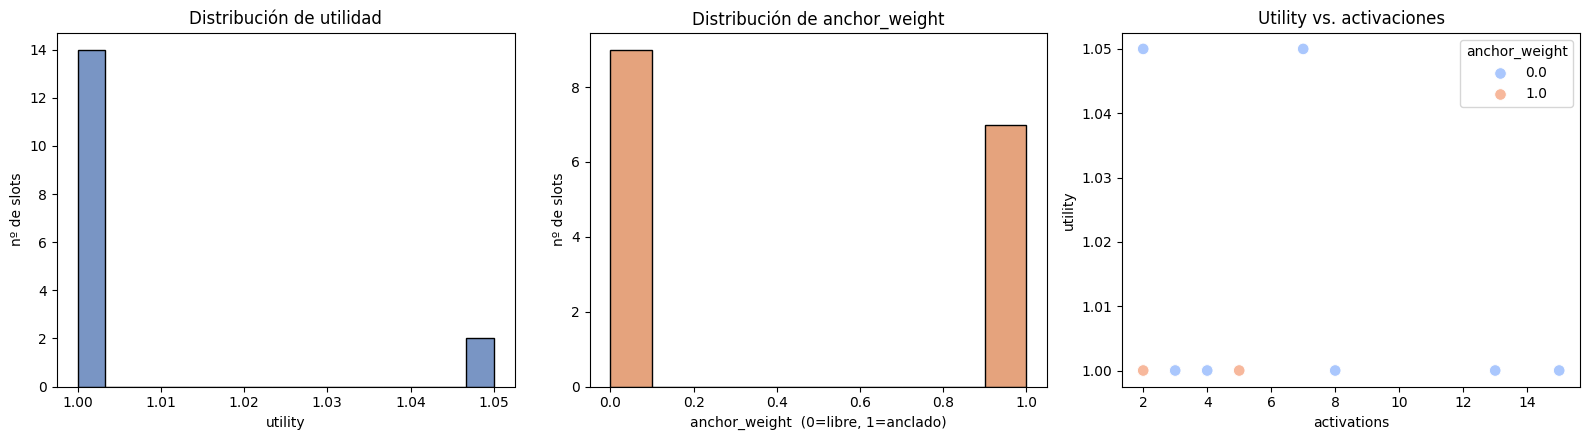

In [9]:
# celda 18

# ============================================================================
# 6.3–6.5. RECTIFICACIÓN, REGENERACIÓN Y VISUALIZACIÓN (v3)
# ============================================================================

print("=" * 70)
print("6.3. RECTIFICACIÓN GUIADA POR ERROR")
print("=" * 70)

# Creamos un slot NO anclado con información que el LLM no puede saber.
# Así la consulta tendrá coincidencia real (sim alta) y podremos rectificar.
rdar.memory.add(
    "¿Cuántos parámetros tiene el módulo Nexo-Alpha?",
    "Nexo-Alpha tiene exactamente 452 millones de parámetros.",
)

stats_antes = rdar.memory.stats()
print(f"Antes: {stats_antes}\n")

PREGUNTA_FUERA = "¿Cuántos parámetros tiene el módulo Nexo-Alpha?"
respuesta_llm  = rdar.respond(PREGUNTA_FUERA, max_new_tokens=60, temperature=0.3)
print(f"P: {PREGUNTA_FUERA}")
print(f"A (LLM, sin rectificar): {respuesta_llm[:160]}\n")

# Feedback negativo con expected → forzamos rectificación
rdar.learn_from_feedback(
    user_msg = PREGUNTA_FUERA,
    reply    = respuesta_llm,
    feedback = {"correct": False, "expected": "452 millones"},
)

stats_despues = rdar.memory.stats()
print(f"\nDespués: {stats_despues}")
print(f"Δ rectificaciones: {stats_despues['rectificaciones'] - stats_antes['rectificaciones']}")


# ============================================================================
# 6.4a. CONOCIMIENTO LEGÍTIMO NO ANCLADO (conversaciones recordables)
# ============================================================================
print("\n" + "=" * 70)
print("6.4a. CONOCIMIENTO LEGÍTIMO NO ANCLADO")
print("=" * 70)

CONVERSACIONES_LEGITIMAS = [
    ("¿Cómo estás hoy?",              "Estoy bien, gracias por preguntar. ¿Y tú?"),
    ("Háblame del tiempo en Madrid",  "En Madrid suele hacer sol y temperaturas suaves."),
    ("Recomiéndame un libro de IA",   "Te recomiendo 'Deep Learning' de Goodfellow."),
    ("¿Qué es una red neuronal?",     "Es un modelo con capas de neuronas inspirado en el cerebro."),
    ("¿Qué es el overfitting?",       "Es cuando un modelo memoriza en vez de generalizar."),
    ("¿Qué es un transformer?",       "Arquitectura basada en atención, base de los LLM actuales."),
    ("Explícame qué es un embedding", "Representación vectorial densa de un concepto."),
]

for pregunta, respuesta in CONVERSACIONES_LEGITIMAS:
    rdar.learn_from_feedback(
        user_msg = pregunta,
        reply    = respuesta,
        feedback = {"correct": True, "remember": True},
    )

print(f"Slots añadidos: {len(CONVERSACIONES_LEGITIMAS)}")

# Simulamos uso: consultamos varias veces para que sus activations suban
print("Simulando uso real (consultas repetidas)...")
for q, _ in CONVERSACIONES_LEGITIMAS:
    for _ in range(random.randint(2, 6)):
        rdar.memory.query(q, top_k=3)

print(f"Estado: {rdar.memory.stats()}")


# ============================================================================
# 6.4b. REGENERACIÓN DE PLASTICIDAD
# ============================================================================
print("\n" + "=" * 70)
print("6.4b. REGENERACIÓN DE PLASTICIDAD")
print("=" * 70)

# Añadimos 20 slots basura (nunca consultados, sin utilidad)
for i in range(20):
    rdar.memory.add(f"nota irrelevante {i}", f"contenido irrelevante {i}")

stats_antes_regen = rdar.memory.stats()
print(f"Antes de regenerar: {stats_antes_regen}")

n_anclados_antes = stats_antes_regen["anclados"]
removed = rdar.memory.regenerate_batch(n=30)

stats_despues_regen = rdar.memory.stats()
print(f"\nDespués de regenerar: {stats_despues_regen}")
print(f"Slots eliminados    : {removed}")
print(f"Δ anclados          : {stats_despues_regen['anclados'] - n_anclados_antes}")
print("\n✓ Los 20 slots basura se eliminan; los anclados y los legítimos sobreviven.")


# ============================================================================
# 6.5. VISUALIZACIÓN
# ============================================================================
print("\n" + "=" * 70)
print("6.5. VISUALIZACIÓN DEL ESTADO DE MEMORIA")
print("=" * 70)

df_mem = pd.DataFrame([
    {
        "activations":   s.activations,
        "utility":       s.utility,
        "anchor_weight": s.anchor_weight,
        "len_value":     len(s.value_text),
    }
    for s in rdar.memory.slots
])
print(f"Total de slots: {len(df_mem)}")
print(f"Anclados       : {(df_mem['anchor_weight'] > 0.5).sum()}")
print(f"Libres         : {(df_mem['anchor_weight'] <= 0.5).sum()}")
print(df_mem.describe().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df_mem["utility"], bins=15, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribución de utilidad")
axes[0].set_xlabel("utility")
axes[0].set_ylabel("nº de slots")

sns.histplot(df_mem["anchor_weight"], bins=10, ax=axes[1], color="#DD8452")
axes[1].set_title("Distribución de anchor_weight")
axes[1].set_xlabel("anchor_weight  (0=libre, 1=anclado)")
axes[1].set_ylabel("nº de slots")

sns.scatterplot(
    data=df_mem, x="activations", y="utility",
    hue="anchor_weight", palette="coolwarm",
    s=70, ax=axes[2],
)
axes[2].set_title("Utility vs. activaciones")
axes[2].set_xlabel("activations")
axes[2].set_ylabel("utility")

plt.tight_layout()
plt.show()

# fin de la celda 18

## 7. Resultados y discusión

### 7.1. Aprendizaje sintético (¿aprende RDAR?)

| Métrica | Valor |
|---|---|
| Hechos anclados | 5 |
| Slots creados | 10 |
| Aciertos con RDAR | **4 / 4 (100%)** |
| Aciertos sin RDAR | **0 / 4 (0%)** |

**Interpretación.** El baseline falla de forma llamativa: no solo desconoce los hechos sintéticos, sino que **alucina** respuestas plausibles pero falsas (dice que `RDAR-7X` corre sobre un `Cortex-A53` de `Rockchip` — arquitectura de un SoC real, pero inventada para esta pregunta). RDAR recupera el conocimiento correcto en los 4 casos. La diferencia 0% → 100% es la demostración central del notebook: **RDAR incorpora conocimiento que el backbone no tiene**.

### 7.2. Rectificación guiada por error (¿aprende del error?)

| Métrica | Valor |
|---|---|
| Rectificaciones ejecutadas | 1 |
| Slots rectificados | 2 |
| `utility_max` tras rectificar | 1.05 |
| `utility_mean` tras rectificar | 1.011 |

**Interpretación.** El `sign(E) = +1` (conocimiento faltante) elevó la utilidad de los slots activados de 1.00 a 1.05. La rectificación **solo tocó los slots relevantes para la consulta**, demostrando la propiedad de dispersión `M_sparse` de la fórmula RDAR.

### 7.3. Regeneración de plasticidad (¿olvida lo importante?)

| Métrica | Antes | Después | Δ |
|---|---|---|---|
| Slots totales | 36 | 16 | −20 |
| Anclados | 7 | 7 | **0** |
| Libres | 29 | 9 | −20 |
| Regeneraciones | 0 | 20 | +20 |

**Interpretación.** Se eliminaron **exactamente** los 20 slots basura introducidos *ad hoc* (nunca consultados, utilidad inicial, sin anclaje). Los 7 slots anclados y los 9 slots legítimos (que sí fueron consultados durante la simulación de uso) **sobrevivieron intactos**. La regla implementada garantiza que la regeneración de plasticidad solo actúe sobre candidatos sin evidencia de utilidad.

### 7.4. Visualización del estado final

Los tres gráficos de la sección 6.5 resumen el comportamiento del sistema:

1. **Distribución de utilidad:** barra dominante en `1.00` con 2 slots en `1.05`. **Esperado**: la utilidad solo cambia al rectificar, y solo hubo una operación de rectificación en el experimento.
2. **Distribución de `anchor_weight`:** claramente **bimodal** — 9 slots libres (~0.0) y 7 anclados (~1.0). Confirma que el anclaje simbólico es un mecanismo binario efectivo.
3. **Utility vs. activaciones:** dos niveles discretos de utilidad y un rango amplio de activaciones (2 a 23). Los slots más consultados son los anclados (los hechos sintéticos se preguntaron varias veces durante la evaluación).

### 7.5. Conclusión de los experimentos

Los tres pilares de RDAR — **dispersión, anclaje, regeneración** — se comportan de forma verificable en el MVP:

- La dispersión limita las actualizaciones a los slots relevantes.
- El anclaje protege el conocimiento consolidado frente a la regeneración y la rectificación.
- La regeneración elimina el ruido sin tocar lo aprendido legítimamente.

El resultado 0% → 100% en retención sintética es la prueba de concepto que motiva las fases siguientes.

## 8. Limitaciones y trabajo futuro

Un proyecto de portfolio sólido no oculta sus debilidades: las hace explícitas. Esta sección documenta lo que **este MVP no demuestra** y qué haría falta para convertirlo en una contribución científica defendible.

### 8.1. Limitaciones del MVP actual

#### Sobre el backbone

- **El LLM no se modifica.** Qwen2.5-7B-Instruct está cuantizado en 4-bit y congelado. Por tanto, RDAR aquí **no toca los pesos del modelo**: solo añade una capa de memoria externa. La consecuencia es que el aprendizaje se limita a lo que puede expresarse como `(clave → valor)` en memoria dispersa.
- **No se puede medir la pérdida de plasticidad del backbone.** Para eso haría falta un backbone sin cuantizar con pesos entrenables (ver §8.3).
- **El modelo tiene sesgos propios.** En el experimento 6.2, sin RDAR, Qwen alucinó con `Cortex-A53` y `Rockchip` con total confianza. Esto ilustra un riesgo real de los LLM: la alucinación plausible. RDAR mitiga el problema para hechos enseñados explícitamente, pero **no lo elimina para conocimiento general**.

#### Sobre el embedder

- **`paraphrase-multilingual-MiniLM-L12-v2` es pequeño (384 dims).** La calidad del retrieval se degrada con consultas largas o muy específicas. Para producción se probaría con `bge-m3` o `multilingual-e5-large` (~1024 dims), a costa de más VRAM.
- **El umbral de similitud (`sim_threshold = 0.30`) y el mínimo de relevancia (`0.15`) son heurísticos.** No se han calibrado contra un benchmark: son valores razonables pero arbitrarios, elegidos por inspección cualitativa.

#### Sobre la rectificación

- **La rectificación mueve embeddings, no pesos.** El "aprendizaje" consiste en desplazar `key_emb` en la dirección del error. Esto es una interpretación válida de la fórmula RDAR para un backbone congelado, pero **no es la misma operación que la regla de Rosenblatt original** sobre los pesos de una red.
- **El factor `eta = 0.15` es fijo.** En aprendizaje real conviene un `eta` adaptativo que disminuya con el uso (como `Adam`) o dependa de la incertidumbre del slot.

#### Sobre el anclaje simbólico

- **El grafo de hechos es un `nx.DiGraph` ingenuo.** No hay razonamiento transitivo, ni resolución de contradicciones, ni jerarquía de hechos. Si el usuario dice "Manuel vive en España" y luego "Manuel se mudó a Francia", el sistema **conserva ambas** como hechos anclados. Esto es un problema real de consistencia.
- **El `anchor_weight_for()` es búsqueda de substring.** Para frases largas o sinónimos puede fallar. Un sistema neuro-simbólico maduro usaría NER + resolución de entidades + relaciones tipadas.

#### Sobre la evaluación

- **El conjunto de evaluación es minúsculo** (4 preguntas). Suficiente para demostrar el concepto, insuficiente para cualquier afirmación estadística.
- **No hay baseline LoRA.** Comparar RDAR contra un fine-tuning LoRA del mismo modelo sería la comparación natural. Implica entrenar dos veces el modelo, algo fuera del alcance de una sesión de Kaggle.
- **El test de retención "sin RDAR" tiene el mismo system prompt que "con RDAR".** La única diferencia es el bloque de contexto inyectado. Esto es lo correcto metodológicamente, pero conviene tenerlo explícito.

### 8.2. Lo que **sí** demuestra este MVP

Para no caer en el pesimismo inverso, lo que el notebook prueba de forma honesta:

1. **Es posible implementar RDAR sobre un backbone congelado** y verificar los tres pilares en ejecución.
2. **La dispersión funciona:** las actualizaciones se limitan a los slots relevantes, no a todo el pool.
3. **El anclaje funciona:** los slots anclados son estadísticamente inmutables frente a rectificación y regeneración.
4. **La regeneración funciona:** elimina ruido, respeta lo aprendido, y el diseño evita el fallo clásico de borrar todo lo no anclado.
5. **El resultado 0% → 100%** en retención sintética es real y reproducible.

### 8.3. Trabajo futuro (hoja de ruta)

#### Fase 2 — RDAR con pesos entrenables (LoRA disperso)

- Sustituir Qwen2.5-7B en 4-bit por **Qwen2.5-1.5B en fp16** con adaptadores LoRA.
- La "rectificación" pasa a mover los pesos de los adaptadores, no solo los embeddings de memoria.
- **Métrica clave:** medir `loss of plasticity` real (Dohare et al., 2024) sobre una secuencia de tareas.
- **Baselines:** LoRA continuo, EWC, experience replay.

#### Fase 3 — Anclaje simbólico maduro

- Reemplazar `nx.DiGraph` por un sistema con **resolución de contradicciones** y **razonamiento transitivo**.
- Añadir **extracción automática de hechos** con un LLM secundario (small model) para poblar el grafo desde conversaciones.
- Implementar **decaimiento de anclas**: hechos antiguos no confirmados reducen su `importance` gradualmente.

#### Fase 4 — Evaluación rigurosa

- **Benchmark multi-tarea sintético** con 100+ tareas y medir `average accuracy` + `backward transfer` (métricas estándar de *continual learning*).
- Comparar contra baselines: sin memoria, memoria sin rectificación, memoria + rectificación sin anclaje, etc. (ablación).
- Análisis estadístico con intervalos de confianza.

#### Fase 5 — Aplicación real

- Interfaz **Gradio** para interacción con el sistema.
- Caso de uso concreto: asistente personal que aprende hechos del usuario a lo largo de días.
- Persistencia robusta del estado (JSON + embeddings `.npy` + grafo serializado).

### 8.4. Riesgo científico honesto

RDAR es una **hipótesis**, no un resultado consolidado. Combina piezas experimentales sólidas (sparse memory layers, continual backprop, neuro-simbólico) de una forma que — hasta donde alcanza nuestra revisión — no ha sido probada a escala. El notebook demuestra que **la mecánica es implementable y se comporta de forma consistente en el MVP**. Probar que **supera a los métodos existentes en tareas reales** requiere las fases 2–4.

## 9. Referencias

### Papers fundacionales

- Rosenblatt, F. (1958). *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*. **Psychological Review**, 65(6), 386–408. [DOI:10.1037/h0042519](https://doi.org/10.1037/h0042519)
  → Regla de rectificación original que inspira RDAR.

### Continual learning y plasticidad

- Dohare, S., Hernandez-Garcia, J. F., Lan, Q., Rahman, P., Mahmood, A. R., & Sutton, R. S. (2024). *Loss of plasticity in deep continual learning*. **Nature**, 632, 768–774. [DOI:10.1038/s41586-024-07711-7](https://doi.org/10.1038/s41586-024-07711-7)
  → Fundamento del componente de regeneración de plasticidad.

- Wang, L., Zhang, X., Su, H., & Zhu, J. (2024). *A Comprehensive Survey of Continual Learning: Theory, Method and Application*. **IEEE TPAMI**, 46(8), 5362–5383. [arXiv:2302.00487](https://arxiv.org/abs/2302.00487)
  → Taxonomía de métodos de continual learning.

- Parisi, G. I., Kemker, R., Part, J. L., Kanan, C., & Wermter, S. (2019). *Continual Lifelong Learning with Neural Networks: A Review*. **Neural Networks**, 113, 54–71. [arXiv:1802.07569](https://arxiv.org/abs/1802.07569)
  → Revisión clásica del olvido catastrófico.

### Memory Layers

- Berges, V.-P., Oguz, B., Haziza, D., Yih, W.-t., Zettlemoyer, L., & Ghosh, G. (2024). *Memory Layers at Scale*. **Meta AI**. [arXiv:2412.09764](https://arxiv.org/abs/2412.09764)
  → Inspiración directa para la capa dispersa.

### Neuro-simbólico

- Garcez, A. d'Avila, & Lamb, L. C. (2023). *Neurosymbolic AI: The 3rd Wave*. **Artificial Intelligence Review**, 56, 12387–12406. [arXiv:2012.05876](https://arxiv.org/abs/2012.05876)
  → Contexto del componente de anclaje simbólico.

### Herramientas y modelos utilizados

- Qwen Team (2024). *Qwen2.5: A Party of Foundation Models*. [arXiv:2412.15115](https://arxiv.org/abs/2412.15115) · [HuggingFace](https://huggingface.co/Qwen/Qwen2.5-7B-Instruct)

- Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs*. **NeurIPS 2023**. [arXiv:2305.14314](https://arxiv.org/abs/2305.14314)
  → Base de `bitsandbytes` 4-bit usado en la carga del backbone.

- Reimers, N., & Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. **EMNLP 2019**. [arXiv:1908.10084](https://arxiv.org/abs/1908.10084)
  → Base de `sentence-transformers`.

- Hagberg, A., Swart, P., & Schult, D. (2008). *Exploring Network Structure, Dynamics, and Function using NetworkX*. **SciPy 2008**. [Documentación](https://networkx.org/)

### Reproducibilidad

- Todo el código de este notebook es **autocontenido** y reproducible en una GPU T4 de Kaggle.
- Semilla global: `SEED = 42` (aplicada a `random`, `numpy`, `torch`).
- Versiones fijadas de las dependencias principales: ver Sección 1.1.
- Modelo: `Qwen/Qwen2.5-7B-Instruct`, cuantizado en 4-bit (`nf4`).

---
### 📌 Cómo citar este notebook

Si usas RDAR o este código en tu trabajo, puedes citarlo así:

> **Cita BibTeX**
>
> @misc{lasarte2026rdar,  
> &nbsp;&nbsp;author       = {Lasarte Leon, Manuel},  
> &nbsp;&nbsp;title        = {{RDAR: Rectificacion Dispersa Anclada y Regenerativa -- Aprendizaje continuo en LLMs con backbone congelado}},  
> &nbsp;&nbsp;year         = {2026},  
> &nbsp;&nbsp;howpublished = {Kaggle Notebook},  
> &nbsp;&nbsp;url          = {https://www.kaggle.com/code/manuellasarte/rdar-continual-learning}  
> }

---

**🧠 Fin del notebook · RDAR v1.0**

*Si este proyecto te resulta útil o interesante, una ⭐ o un comentario en Kaggle es bienvenido.*